In [1]:
import sys; sys.path.append("..")
import numpy as np, matplotlib.pyplot as plt
from data import get_splits, one_hot
from metrics import evaluate, Timer
d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]

In [5]:
#Bai 1: accuracy khong dung vong lap for
y_fake = np.random.randint(0, 10, len(yva))
print("Accuracy: ", (yva == y_fake).mean())
#Bai 2: Trung binh anh cua tung lop bang mot phep nhan ma tran
Y = one_hot(ytr)
mean_fast = (Y.T @ Xtr) / Y.sum(0)[:, None]
mean_loop = np.stack([Xtr[ytr == c].mean(0) for c in range(10)])
print("Difference between fast and slow mean calculation:", np.abs(mean_fast - mean_loop).max())
print(np.allclose(mean_fast, mean_loop, atol = 1e-5))
#Bai 3: vong for va vecto hoa
mu  = Xtr.mean(0)
with Timer() as t1:
    r1 = np.array([np.sum((x - mu) ** 2) for x in Xtr[:1000]])
with Timer() as t2:
    r2 = np.sum((Xtr[:1000] - mu) ** 2, axis=1)
print("Difference between fast and slow distance calculation:", np.abs(r1 - r2).max())
print(t1.seconds, t2.seconds, np.allclose(r1, r2, atol = 1e-5))

Accuracy:  0.0985
Difference between fast and slow mean calculation: 1.6391277e-05
True
Difference between fast and slow distance calculation: 0.0
0.0027369000017642975 0.0019752001389861107 True


In [6]:
from naive_bayes import GaussianNB
import pandas as pd

with Timer() as t_fit:
    gnb = GaussianNB(var_smoothing=1e-9).fit(Xtr, ytr)
with Timer() as t_pred:
    p_va = gnb.predict(Xva)
p_tr = gnb.predict(Xtr)

r_tr, r_va = evaluate(ytr, p_tr), evaluate(yva, p_va)
print(f"fit {t_fit.seconds:.2f}s | predict(val) {t_pred.seconds:.2f}s")
print("train acc", r_tr["accuracy"], "| val acc", r_va["accuracy"], "| val F1", r_va["f1_macro"])

fit 0.44s | predict(val) 0.57s
train acc 0.57668 | val acc 0.576 | val F1 0.5253725268686031


1e-09 0.576
1e-07 0.6083
1e-05 0.6535
0.001 0.7366
0.01 0.7801
0.1 0.7978
1.0 0.7332


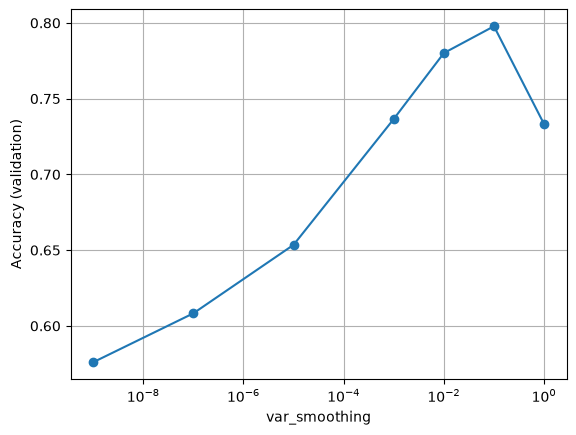

In [7]:
grid = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]
accs = []
for vs in grid:
    m = GaussianNB(var_smoothing=vs).fit(Xtr, ytr)
    accs.append(evaluate(yva, m.predict(Xva))["accuracy"])
    print(vs, accs[-1])

plt.figure(); plt.semilogx(grid, accs, "o-")
plt.xlabel("var_smoothing"); plt.ylabel("Accuracy (validation)")
plt.grid(True); plt.savefig("../report/gnb_var_smoothing.png", dpi=150)
plt.show()

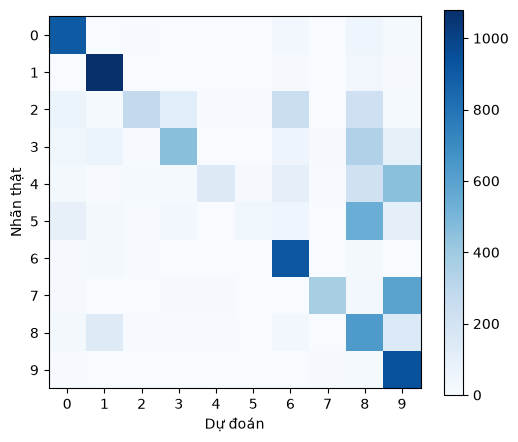

In [8]:
C = r_va["confusion_matrix"]
plt.figure(figsize=(6, 5)); plt.imshow(C, cmap="Blues"); plt.colorbar()
plt.xlabel("Dự đoán"); plt.ylabel("Nhãn thật"); plt.xticks(range(10)); plt.yticks(range(10))
plt.savefig("../report/gnb_confusion_val.png", dpi=150); plt.show()

In [ ]:

print("Train acc (%):", round(r_tr["accuracy"] * 100, 2))
print("Val acc (%)  :", round(r_va["accuracy"] * 100, 2))
print("Val F1 macro (%):", round(r_va["f1_macro"] * 100, 2))
print("Thời gian fit (s):", round(t_fit.seconds, 3))
print("Thời gian predict val (s):", round(t_pred.seconds, 3))

best = int(np.argmax(accs))
print("var_smoothing tốt nhất:", grid[best])
print("Val acc tại giá trị đó (%):", round(accs[best] * 100, 2))

Train acc (%): 57.67
Val acc (%)  : 57.6
Val F1 macro (%): 52.54
Thời gian fit (s): 0.437
Thời gian predict val (s): 0.575
var_smoothing tốt nhất: 0.1
Val acc tại giá trị đó (%): 79.78
